# 03 · Insights, charts and exports

**Goal:** answer the business questions with charts, test how robust the findings are, and export the tables behind the Excel planner and the Power BI dashboard.

1. How are sales trending?
2. Where are we losing sales to empty shelves?
3. Is it a store problem or a supply problem?
4. Is the loss concentrated, or spread across many gaps?
5. How sensitive is the estimate to the stockout test?
6. Which lines matter most, and how forecastable are they?
7. When does demand spike?
8. What is out of stock right now?
9. Export the tables for Excel and Power BI

In [1]:
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import font_manager, patches, ticker

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMAGES = ROOT / "images"
PROCESSED = ROOT / "data" / "processed"
IMAGES.mkdir(exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(ROOT / "data" / "inventory.duckdb"))


def q(sql):
    return con.sql(sql).df()

**Chart style.** One colourblind-safe palette, thin marks, light gridlines, and labels in grey ink rather than series colours.

In [2]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, LIGHT_BLUE = "#2a78d6", "#eb6834", "#86b6ef"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Inter", "Segoe UI", "Helvetica Neue", "Arial"] if f in installed), "DejaVu Sans")
plt.rcParams.update({
    "font.family": FONT, "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.facecolor": SURFACE, "figure.facecolor": SURFACE,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlepad": 12,
    "grid.color": GRID, "grid.linewidth": 1, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
})


def tidy(ax, grid="y"):
    """Hairline grid on one axis, no tick marks, baseline only."""
    ax.grid(axis=grid)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    if grid == "x":
        ax.spines["bottom"].set_visible(False)
    else:
        ax.spines["left"].set_visible(False)


def rounded_bars(ax, positions, values, thickness=0.55, color=BLUE, horizontal=True, radius_px=4):
    """Bars with a 4 px rounded data end and a square end at the baseline."""
    ax.figure.canvas.draw()
    box = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    px_x, px_y = box.width / (x1 - x0), box.height / abs(y1 - y0)
    colors = color if isinstance(color, (list, tuple)) else [color] * len(values)
    for pos, val, col in zip(positions, values, colors):
        if val == 0:
            continue
        if horizontal:
            r = min(radius_px / px_x, abs(val) / 2)
            start = min(0, val)
            ax.add_patch(patches.FancyBboxPatch((start, pos - thickness / 2), abs(val), thickness,
                         boxstyle=f"round,pad=0,rounding_size={r}", mutation_aspect=px_x / px_y,
                         facecolor=col, edgecolor="none", zorder=3))
            square_from = 0 if val > 0 else val + r
            ax.add_patch(patches.Rectangle((square_from, pos - thickness / 2), abs(val) - r, thickness,
                         facecolor=col, edgecolor="none", zorder=3))
        else:
            r = min(radius_px / px_y, abs(val) / 2)
            start = min(0, val)
            ax.add_patch(patches.FancyBboxPatch((pos - thickness / 2, start), thickness, abs(val),
                         boxstyle=f"round,pad=0,rounding_size={r * px_y / px_x}",
                         mutation_aspect=px_x / px_y, facecolor=col, edgecolor="none", zorder=3))
            square_from = 0 if val > 0 else val + r
            ax.add_patch(patches.Rectangle((pos - thickness / 2, square_from), thickness, abs(val) - r,
                         facecolor=col, edgecolor="none", zorder=3))


def save(fig, name):
    fig.savefig(IMAGES / name, bbox_inches="tight", facecolor=SURFACE)

## 1. How are sales trending?

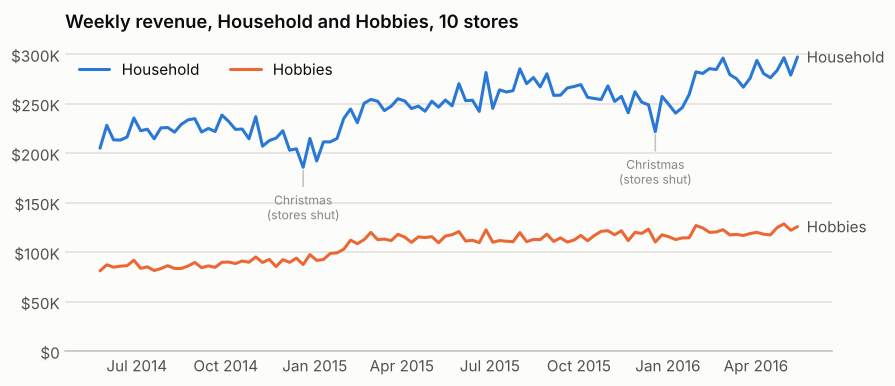

Revenue growth, last 52 weeks vs the 52 before: {'HOBBIES': '+21.8%', 'HOUSEHOLD': '+16.9%'}


In [3]:
weekly = q("""
    SELECT week_start, cat_id, SUM(revenue) AS revenue
    FROM dash_weekly_sales
    GROUP BY week_start, cat_id
    ORDER BY week_start
""").pivot(index="week_start", columns="cat_id", values="revenue")

fig, ax = plt.subplots(figsize=(9, 3.6))
for cat, colour, label in [("HOUSEHOLD", BLUE, "Household"), ("HOBBIES", ORANGE, "Hobbies")]:
    ax.plot(weekly.index, weekly[cat] / 1000, color=colour, label=label)
    ax.annotate(label, (weekly.index[-1], weekly[cat].iloc[-1] / 1000), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK_2)
for christmas in pd.to_datetime(["2014-12-25", "2015-12-25"]):
    week = weekly.index[weekly.index <= christmas].max()
    ax.annotate("Christmas\n(stores shut)", (week, weekly.loc[week, "HOUSEHOLD"] / 1000), xytext=(0, -34),
                textcoords="offset points", ha="center", color=MUTED, fontsize=8,
                arrowprops={"arrowstyle": "-", "color": AXIS, "lw": 1})
ax.set_title("Weekly revenue, Household and Hobbies, 10 stores")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"${v:,.0f}K" if v else "$0"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(0, None)
ax.legend(loc="upper left", ncols=2)
tidy(ax)
save(fig, "01_weekly_revenue.png")
plt.show()

growth = weekly.iloc[-52:].sum() / weekly.iloc[-104:-52].sum() - 1
print("Revenue growth, last 52 weeks vs the 52 before:", growth.map("{:+.1%}".format).to_dict())

## 2. Where are we losing sales to empty shelves?
A **likely stockout** is a run of zero-sale days that would be near-impossible (under 1 in 100,000) if the item were on the shelf, given its normal daily sales (`sql/05_stockout_runs.sql`). Each run is valued at normal daily sales × shelf price.

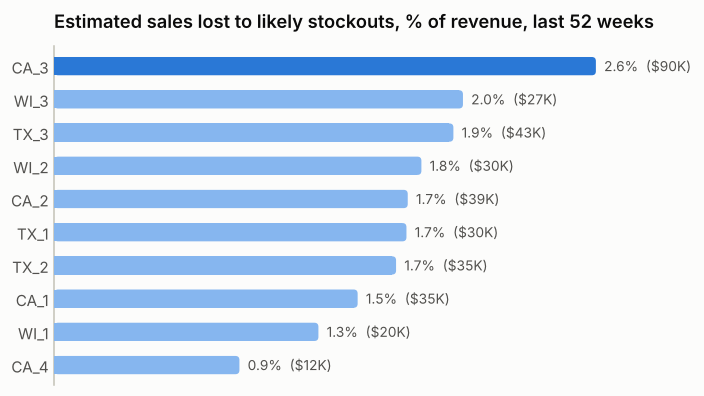

,store_id,revenue,lost_revenue,stockouts,lost_pct
6,CA_3,3421873.72,90340.19,1147.0,2.64
9,WI_3,1346569.25,26829.28,560.0,1.99
8,TX_3,2204661.33,42898.39,709.0,1.95
4,WI_2,1673902.64,29961.24,536.0,1.79
5,CA_2,2240355.93,38609.13,863.0,1.72
1,TX_1,1726081.97,29638.73,591.0,1.72
2,TX_2,2108004.10,35130.13,669.0,1.67
0,CA_1,2337693.54,34580.89,807.0,1.48
3,WI_1,1575607.43,20296.11,414.0,1.29
7,CA_4,1294324.22,11691.50,346.0,0.90


In [4]:
by_store = q("""
    SELECT store_id,
           SUM(revenue_52w)      AS revenue,
           SUM(lost_revenue_52w) AS lost_revenue,
           SUM(stockouts_52w)    AS stockouts
    FROM dash_item_store_summary
    GROUP BY store_id
""")
by_store["lost_pct"] = 100 * by_store["lost_revenue"] / by_store["revenue"]
by_store = by_store.sort_values("lost_pct")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.set_ylim(-0.6, len(by_store) - 0.4)
ax.set_xlim(0, by_store["lost_pct"].max() * 1.18)
worst = by_store["lost_pct"].idxmax()
rounded_bars(ax, range(len(by_store)), by_store["lost_pct"].tolist(),
             color=[BLUE if i == worst else LIGHT_BLUE for i in by_store.index])
for y, (pct, lost) in enumerate(zip(by_store["lost_pct"], by_store["lost_revenue"])):
    ax.text(pct + 0.04, y, f"{pct:.1f}%  (${lost / 1000:,.0f}K)", va="center", color=INK_2, fontsize=9)
ax.set_yticks(range(len(by_store)), by_store["store_id"])
ax.set_title("Estimated sales lost to likely stockouts, % of revenue, last 52 weeks")
tidy(ax, grid="x")
ax.grid(False)
ax.xaxis.set_visible(False)  # every bar carries its own value label
save(fig, "02_lost_sales_by_store.png")
plt.show()

by_store.sort_values("lost_pct", ascending=False).round(2)

In [5]:
by_dept = q("""
    SELECT dept_id,
           ROUND(SUM(revenue_52w), 0)      AS revenue,
           ROUND(SUM(lost_revenue_52w), 0) AS lost_revenue,
           ROUND(100 * SUM(lost_revenue_52w) / SUM(revenue_52w), 2) AS lost_pct
    FROM dash_item_store_summary
    GROUP BY dept_id
    ORDER BY lost_pct DESC
""")
by_abc = q("""
    SELECT abc,
           COUNT(*)                                                               AS item_stores,
           ROUND(100 * SUM(lost_revenue_52w) / SUM(SUM(lost_revenue_52w)) OVER (), 1) AS pct_of_lost_revenue,
           ROUND(100 * SUM(lost_revenue_52w) / SUM(revenue_52w), 2)               AS lost_pct_of_own_revenue
    FROM dash_item_store_summary
    GROUP BY abc
    ORDER BY abc
""")
display(by_dept)
display(by_abc)

,dept_id,revenue,lost_revenue,lost_pct
0,HOUSEHOLD_1,10555490.0,247235.0,2.34
1,HOBBIES_2,301018.0,5151.0,1.71
2,HOBBIES_1,5789208.0,68992.0,1.19
3,HOUSEHOLD_2,3283358.0,38598.0,1.18


,abc,item_stores,pct_of_lost_revenue,lost_pct_of_own_revenue
0,A,6168,86.4,1.95
1,B,4891,10.9,1.32
2,C,5061,2.7,0.98


## 3. Store problem or supply problem?
When the same item is out in three or more stores at the same time, the cause is usually upstream: the supplier or the distribution centre (`sql/06_network_gaps.sql`).

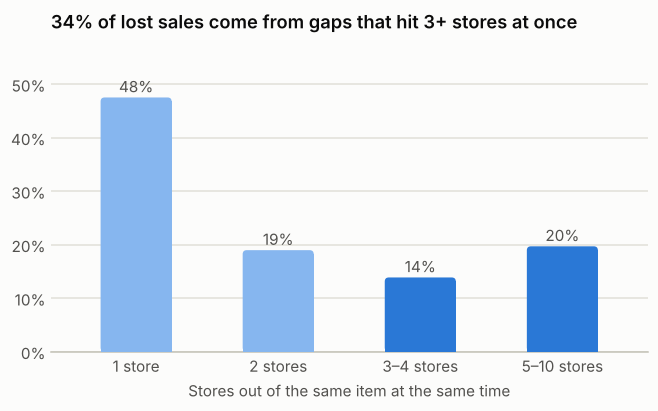

,stores_out,runs,lost_revenue,pct_of_lost
0,1 store,3076,171013.1,47.5
1,2 stores,1679,68247.7,19.0
2,3–4 stores,1251,49879.1,13.9
3,5–10 stores,636,70835.7,19.7


In [6]:
net = q("""
    SELECT CASE
             WHEN stores_out_together = 1 THEN '1 store'
             WHEN stores_out_together = 2 THEN '2 stores'
             WHEN stores_out_together <= 4 THEN '3–4 stores'
             ELSE '5–10 stores'
           END AS stores_out,
           COUNT(*)              AS runs,
           SUM(est_lost_revenue) AS lost_revenue
    FROM dash_stockouts_52w
    GROUP BY stores_out
    ORDER BY stores_out
""")
net["pct_of_lost"] = 100 * net["lost_revenue"] / net["lost_revenue"].sum()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.set_xlim(-0.6, len(net) - 0.4)
ax.set_ylim(0, net["pct_of_lost"].max() * 1.2)
rounded_bars(ax, range(len(net)), net["pct_of_lost"].tolist(), horizontal=False, thickness=0.5,
             color=[LIGHT_BLUE, LIGHT_BLUE, BLUE, BLUE])
for x, pct in enumerate(net["pct_of_lost"]):
    ax.text(x, pct + 1, f"{pct:.0f}%", ha="center", color=INK_2)
ax.set_xticks(range(len(net)), net["stores_out"])
ax.set_xlabel("Stores out of the same item at the same time")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
network_share = net.loc[net["stores_out"].isin(["3–4 stores", "5–10 stores"]), "pct_of_lost"].sum()
ax.set_title(f"{network_share:.0f}% of lost sales come from gaps that hit 3+ stores at once")
tidy(ax)
save(fig, "03_network_gaps.png")
plt.show()
net.round(1)

**The costliest network gap.** In late August 2015 one household item went to zero in all ten stores, across three states, for about two weeks. No store-level ordering problem looks like that.

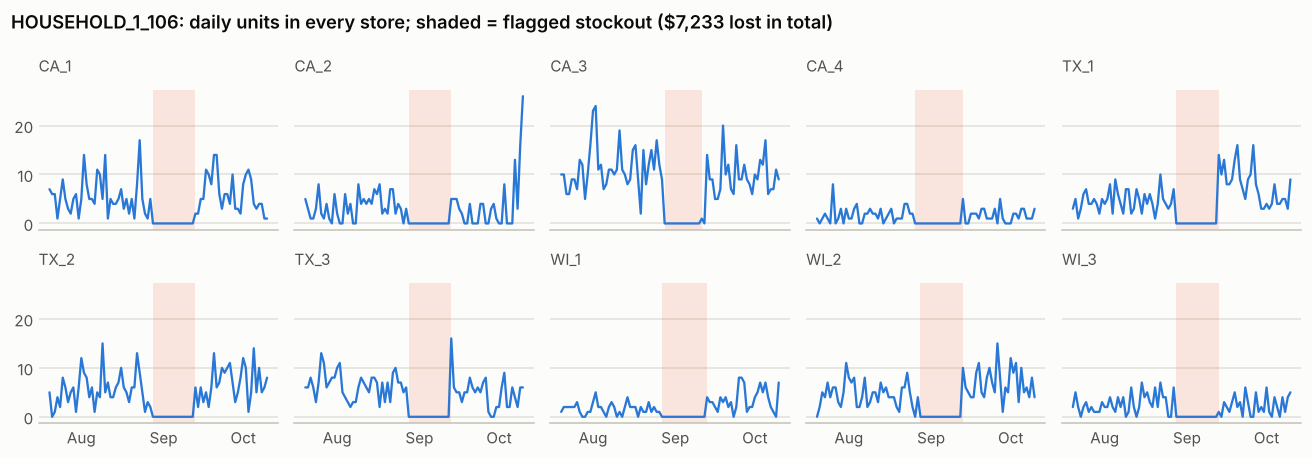

,store_id,run_start,run_end,run_days,est_lost_revenue
3,CA_1,2015-08-28,2015-09-12,16,832.93
6,CA_2,2015-08-28,2015-09-12,16,612.52
0,CA_3,2015-08-28,2015-09-10,14,1341.02
9,CA_4,2015-08-26,2015-09-12,18,273.91
5,TX_1,2015-08-28,2015-09-12,16,679.16
2,TX_2,2015-08-28,2015-09-12,16,866.25
1,TX_3,2015-08-28,2015-09-12,16,1078.96
8,WI_1,2015-08-27,2015-09-12,17,345.83
4,WI_2,2015-08-28,2015-09-12,16,735.54
7,WI_3,2015-08-28,2015-09-12,16,466.44


In [7]:
example_item = "HOUSEHOLD_1_106"
daily = q(f"""
    SELECT store_id, date, units
    FROM sales_daily
    WHERE item_id = '{example_item}' AND date BETWEEN DATE '2015-07-20' AND DATE '2015-10-10'
    ORDER BY store_id, date
""")
runs = q(f"""
    SELECT store_id, run_start, run_end, run_days, est_lost_revenue
    FROM dash_stockouts_52w
    WHERE item_id = '{example_item}' AND run_start BETWEEN DATE '2015-08-20' AND DATE '2015-09-05'
""")
fig, axes = plt.subplots(2, 5, figsize=(12, 4.2), sharex=True, sharey=True)
for ax, (store, d) in zip(axes.flat, daily.groupby("store_id")):
    for _, r in runs[runs["store_id"] == store].iterrows():
        ax.axvspan(r["run_start"], r["run_end"] + pd.Timedelta(days=1), color=ORANGE, alpha=0.15, lw=0)
    ax.plot(d["date"], d["units"], color=BLUE, lw=1.5)
    ax.set_title(store, fontsize=10, fontweight="normal", color=INK_2)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    tidy(ax)
fig.suptitle(f"{example_item}: daily units in every store; shaded = flagged stockout "
             f"(${runs['est_lost_revenue'].sum():,.0f} lost in total)",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
save(fig, "04_stockout_example.png")
plt.show()
runs.sort_values("store_id")

In [8]:
same_week = q("""
    SELECT COUNT(DISTINCT item_id) AS items_out_in_all_10_stores
    FROM dash_stockouts_52w
    WHERE stores_out_together = 10
      AND run_start BETWEEN DATE '2015-08-24' AND DATE '2015-08-30'
""")
same_week

,items_out_in_all_10_stores
0,3


## 4. Is the loss concentrated, or spread across many gaps?

In [9]:
lost = q("SELECT est_lost_revenue FROM dash_stockouts_52w ORDER BY est_lost_revenue DESC")["est_lost_revenue"]
cum_share = lost.cumsum() / lost.sum()
print(f"Likely stockouts in the last 52 weeks: {len(lost):,}")
for n in [50, 500, 1000]:
    print(f"The {n:>5,} most expensive gaps hold {cum_share.iloc[n - 1]:.0%} of estimated lost revenue")
print(f"Median gap: ${lost.median():,.0f}; average gap: ${lost.mean():,.0f}")

Likely stockouts in the last 52 weeks: 6,642
The    50 most expensive gaps hold 10% of estimated lost revenue
The   500 most expensive gaps hold 38% of estimated lost revenue
The 1,000 most expensive gaps hold 55% of estimated lost revenue
Median gap: $24; average gap: $54


The 50 worst gaps hold only about a tenth of the loss. Fixing a few big cases will not solve it: the loss is spread across thousands of small gaps, which calls for a **system** (reorder points and a weekly exception report), not one-off firefighting.

## 5. How sensitive is the estimate to the stockout test?
The test flags a gap when its chance under normal sales is below 1 in 100,000. Re-running `05_stockout_runs.sql` with looser and stricter bars shows how much the headline depends on that choice.

In [10]:
sql_05 = (ROOT / "sql" / "05_stockout_runs.sql").read_text()
rows = []
for bar in ["0.001", "0.0001", "0.00001", "0.000001"]:
    test_sql = (sql_05.replace("0.00001 AS max_chance", f"{bar} AS max_chance")
                      .replace("CREATE OR REPLACE TABLE stockout_runs AS",
                               "CREATE OR REPLACE TEMP TABLE stockout_runs_test AS"))
    con.execute(test_sql)
    result = q("""
        SELECT COUNT(*) AS likely_stockouts_52w, ROUND(SUM(est_lost_revenue), 0) AS est_lost_revenue_52w
        FROM stockout_runs_test
        WHERE likely_cause = 'Likely stockout'
          AND run_start > (SELECT MAX(date) - 364 FROM sales_daily)
    """)
    rows.append({"chance_bar": f"1 in {round(1 / float(bar)):,}", **result.iloc[0].to_dict()})
con.execute("DROP TABLE stockout_runs_test")
sensitivity = pd.DataFrame(rows)
base = sensitivity.loc[sensitivity["chance_bar"] == "1 in 100,000", "est_lost_revenue_52w"].iloc[0]
sensitivity["vs_chosen_bar"] = (sensitivity["est_lost_revenue_52w"] / base).map("{:.0%}".format)
sensitivity

,chance_bar,likely_stockouts_52w,est_lost_revenue_52w,vs_chosen_bar
0,"1 in 1,000",18896.0,695546.0,193%
1,"1 in 10,000",10384.0,468315.0,130%
2,"1 in 100,000",6642.0,359976.0,100%
3,"1 in 1,000,000",4563.0,291350.0,81%


A looser bar roughly doubles the estimate but would include many gaps that happen by chance; a ten-times stricter bar still keeps about four-fifths of it. The chosen figure is a **conservative** estimate of lost sales.

## 6. Which lines matter most, and how forecastable are they?

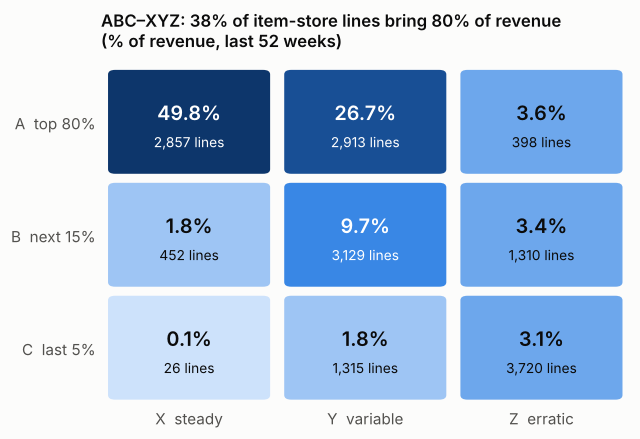

In [11]:
matrix = q("SELECT abc, xyz, item_stores, pct_of_revenue FROM abc_xyz_matrix")
pct = matrix.pivot(index="abc", columns="xyz", values="pct_of_revenue").reindex(index=list("ABC"), columns=list("XYZ"))
count = matrix.pivot(index="abc", columns="xyz", values="item_stores").reindex(index=list("ABC"), columns=list("XYZ"))
bins = [0, 1, 2.5, 5, 10, 20, 35, 101]

fig, ax = plt.subplots(figsize=(6.2, 4))
for i, abc in enumerate("ABC"):
    for j, xyz in enumerate("XYZ"):
        value = pct.loc[abc, xyz]
        step = np.digitize(value, bins) - 1
        fill = BLUE_RAMP[step]
        ax.add_patch(patches.FancyBboxPatch((j + 0.04, 2 - i + 0.04), 0.92, 0.92,
                     boxstyle="round,pad=0,rounding_size=0.04", facecolor=fill, edgecolor="none"))
        ink = "#ffffff" if step >= 3 else INK
        ax.text(j + 0.5, 2 - i + 0.58, f"{value:.1f}%", ha="center", va="center", color=ink,
                fontsize=13, fontweight="semibold")
        ax.text(j + 0.5, 2 - i + 0.32, f"{count.loc[abc, xyz]:,} lines", ha="center", va="center",
                color=ink, fontsize=9)
ax.set_xlim(0, 3)
ax.set_ylim(0, 3)
ax.set_xticks([0.5, 1.5, 2.5], ["X  steady", "Y  variable", "Z  erratic"])
ax.set_yticks([2.5, 1.5, 0.5], ["A  top 80%", "B  next 15%", "C  last 5%"])
ax.tick_params(length=0)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
a_lines = count.loc["A"].sum() / count.values.sum()
ax.set_title(f"ABC–XYZ: {a_lines:.0%} of item-store lines bring 80% of revenue\n"
             "(% of revenue, last 52 weeks)", fontsize=11)
save(fig, "05_abc_xyz_matrix.png")
plt.show()

**Forecast accuracy by XYZ class.** A simple backtest over the last 13 full weeks: forecast each week as the average of the four weeks before it, and compare with the naive "same as last week" and "same week last year" methods. The error measure is WAPE (total absolute error ÷ total units).

,WAPE % · last_week,WAPE % · moving_avg_4w,WAPE % · same_week_last_year
X,33.2,28.2,45.3
Y,57.4,49.1,76.5
Z,78.3,70.9,110.9
All,46.4,40.0,63.1


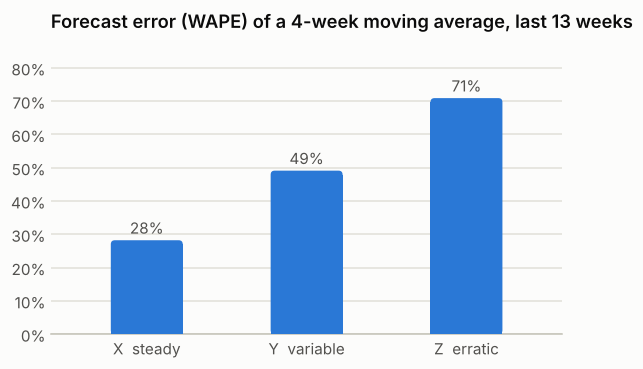

In [12]:
weeks = q("""
    SELECT m.item_id, m.store_id, m.wm_yr_wk, m.units, a.abc, a.xyz
    FROM mart_item_store_week AS m
    JOIN abc_xyz AS a USING (item_id, store_id)
    WHERE m.days_in_week = 7
    ORDER BY m.item_id, m.store_id, m.wm_yr_wk
""")
by_series = weeks.groupby(["item_id", "store_id"])["units"]
weeks["last_week"] = by_series.shift(1)
weeks["moving_avg_4w"] = by_series.transform(lambda s: s.shift(1).rolling(4).mean())
weeks["same_week_last_year"] = by_series.shift(52)

test = weeks[weeks["wm_yr_wk"].isin(sorted(weeks["wm_yr_wk"].unique())[-13:])].dropna()
methods = ["last_week", "moving_avg_4w", "same_week_last_year"]


def wape(df, method):
    return (df[method] - df["units"]).abs().sum() / df["units"].sum()


accuracy = pd.DataFrame({
    xyz: {m: wape(group, m) for m in methods} for xyz, group in test.groupby("xyz")
}).T
accuracy.loc["All"] = {m: wape(test, m) for m in methods}
display((100 * accuracy).round(1).rename(columns=lambda c: f"WAPE % · {c}"))

fig, ax = plt.subplots(figsize=(6, 3.4))
classes = ["X", "Y", "Z"]
values = (100 * accuracy.loc[classes, "moving_avg_4w"]).tolist()
ax.set_xlim(-0.6, 2.6)
ax.set_ylim(0, max(values) * 1.22)
rounded_bars(ax, range(3), values, horizontal=False, thickness=0.45)
for x, v in enumerate(values):
    ax.text(x, v + 2, f"{v:.0f}%", ha="center", color=INK_2)
ax.set_xticks(range(3), ["X  steady", "Y  variable", "Z  erratic"])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_title("Forecast error (WAPE) of a 4-week moving average, last 13 weeks")
tidy(ax)
save(fig, "06_forecast_error.png")
plt.show()

The 4-week moving average beats both naive methods for every class, but its error rises from under 30% on steady X lines to about 70% on erratic Z lines. Automate X; give Z lines buffer stock and a human review.

## 7. When does demand spike?

In [13]:
drivers = q("""
    SELECT driver, dept_id, avg_uplift
    FROM demand_drivers
    WHERE driver_type = 'Event'
""")
top = drivers.sort_values("avg_uplift", ascending=False).head(6)
bottom = drivers[drivers["driver"] != "Christmas"].sort_values("avg_uplift").head(3)
display(pd.concat([top, bottom]).assign(avg_uplift=lambda d: d["avg_uplift"].map("{:+.0%}".format)))
display(q("SELECT dept_id, days, avg_uplift FROM demand_drivers WHERE driver_type = 'SNAP payment day' ORDER BY dept_id"))

,driver,dept_id,avg_uplift
72,Halloween,HOBBIES_2,+67%
109,Cinco De Mayo,HOBBIES_2,+43%
116,VeteransDay,HOBBIES_2,+28%
114,LaborDay,HOUSEHOLD_1,+26%
44,Chanukah End,HOBBIES_2,+26%
26,Pesach End,HOBBIES_2,+23%
40,Thanksgiving,HOBBIES_1,-52%
11,NewYear,HOBBIES_2,-45%
3,IndependenceDay,HOBBIES_2,-44%


,dept_id,days,avg_uplift
0,HOBBIES_1,661,0.026
1,HOBBIES_2,661,-0.004
2,HOUSEHOLD_1,661,0.040
3,HOUSEHOLD_2,661,0.019


Halloween lifts Hobbies (HOBBIES_2) by about two-thirds and Labor Day lifts Household by about a quarter, so those weeks need stock built ahead. SNAP payment days barely move these non-food ranges (+0 to +4%), so they need no special planning here.

## 8. What is out of stock right now?
Gaps still open on the last day of data (22 May 2016), ranked by the sales they lose each day.

In [14]:
open_now = q("""
    SELECT s.store_id, s.item_id, s.segment, s.avg_daily_demand, s.current_price,
           ROUND(r.baseline_daily_units * s.current_price, 2) AS lost_revenue_per_day,
           r.run_start, r.run_days
    FROM dash_stockouts_52w AS r
    JOIN dash_item_store_summary AS s USING (item_id, store_id)
    WHERE r.ongoing_at_data_end
    ORDER BY lost_revenue_per_day DESC, s.store_id, s.item_id
""")
print(f"{len(open_now)} item-stores out of stock now, losing about ${open_now['lost_revenue_per_day'].sum():,.0f} a day")
open_now.head(10)

47 item-stores out of stock now, losing about $277 a day


,store_id,item_id,segment,avg_daily_demand,current_price,lost_revenue_per_day,run_start,run_days
0,CA_3,HOUSEHOLD_1_177,AY,6.021,5.97,22.17,2016-05-06,17
1,CA_1,HOBBIES_1_064,AX,1.773,12.97,19.46,2016-05-06,17
2,CA_3,HOUSEHOLD_1_310,AX,5.787,5.97,16.10,2016-05-07,16
3,TX_3,HOUSEHOLD_1_096,AY,4.609,3.97,15.24,2016-05-10,13
4,WI_3,HOUSEHOLD_1_050,AX,4.427,3.97,14.25,2016-05-09,14
5,CA_2,HOUSEHOLD_2_044,AX,3.633,3.48,13.36,2016-05-11,12
6,CA_3,HOUSEHOLD_1_173,AX,11.753,0.97,11.55,2016-05-17,6
7,CA_3,HOBBIES_1_266,AY,2.014,4.86,11.37,2016-05-05,18
8,CA_2,HOUSEHOLD_2_389,AY,5.160,1.97,10.97,2016-05-19,4
9,CA_3,HOUSEHOLD_1_407,CZ,NaN,5.24,8.80,2016-04-26,27


## 9. Export the tables for Excel and Power BI
Small, aggregated tables only; raw M5 data stays out of the repository.

In [15]:
exports = {
    "dash_kpis": "SELECT * FROM dash_kpis",
    "dash_weekly_sales": "SELECT * FROM dash_weekly_sales",
    "dash_item_store_summary": "SELECT * FROM dash_item_store_summary",
    "dash_stockouts_52w": "SELECT * FROM dash_stockouts_52w",
    "dash_lost_sales_by_store": "SELECT * FROM dash_lost_sales_by_store",
    "dash_slow_dead": "SELECT * FROM dash_slow_dead",
    "abc_xyz_matrix": "SELECT * FROM abc_xyz_matrix",
    "demand_drivers": "SELECT * FROM demand_drivers ORDER BY driver_type, driver, dept_id",
    "reorder_points": "SELECT * FROM reorder_points ORDER BY store_id, item_id, lead_time_days",
    "dim_item": "SELECT * FROM items ORDER BY item_id",
    "dim_store": "SELECT * FROM stores ORDER BY store_id",
    "dim_date": """
        SELECT date, wm_yr_wk, weekday, month, year, event_name_1, event_type_1,
               MIN(date) OVER (PARTITION BY wm_yr_wk) AS week_start
        FROM calendar ORDER BY date
    """,
}
for name, sql in exports.items():
    df = q(sql)
    df.to_csv(PROCESSED / f"{name}.csv", index=False)
    print(f"{name + '.csv':<30} {len(df):>7,} rows")

forecast_table = (100 * accuracy).round(1).reset_index(names="xyz")
forecast_table.to_csv(PROCESSED / "forecast_accuracy.csv", index=False)
sensitivity.to_csv(PROCESSED / "stockout_test_sensitivity.csv", index=False)

dash_kpis.csv                        1 rows
dash_weekly_sales.csv            4,160 rows


dash_item_store_summary.csv     16,120 rows


dash_stockouts_52w.csv           6,642 rows
dash_lost_sales_by_store.csv        40 rows
dash_slow_dead.csv                 332 rows
abc_xyz_matrix.csv                   9 rows
demand_drivers.csv                 124 rows
reorder_points.csv              18,504 rows
dim_item.csv                     1,612 rows
dim_store.csv                       10 rows


dim_date.csv                       730 rows


In [16]:
con.close()